In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_results.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

NEIGHBOR_RANGE = list(range(1, 21))
print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)

200 rows  |  53 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,...,cat_wrong_task,cat_too_generic,cat_truncated_incomplete,cat_correct_domain,cat_correct_task,cat_methodology_partially_correct,cat_scientific_language,cat_coherent_structure,num_of_neighbors,is_error
0,769,2942669846,Reinforcement learning usually makes use of nu...,This paper presents a novel approach to deep r...,0.3200,0.0807,0.2222,0.8730,0.8491,0.8609,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,4,False
1,2012,2913127348,Gatherings of thousands to millions of people ...,This paper presents a novel deep convolutional...,0.3071,0.0216,0.1214,0.8445,0.8317,0.8380,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,8,False
2,3364,2942522480,"Recently, a method called the Mutual Informati...",This paper presents a novel application of the...,0.3518,0.0590,0.1694,0.8184,0.8342,0.8262,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,4,False


In [5]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour count (1-20)."""
    values = [series.get(n, np.nan) for n in NEIGHBOR_RANGE]

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(NEIGHBOR_RANGE, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(NEIGHBOR_RANGE)
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()

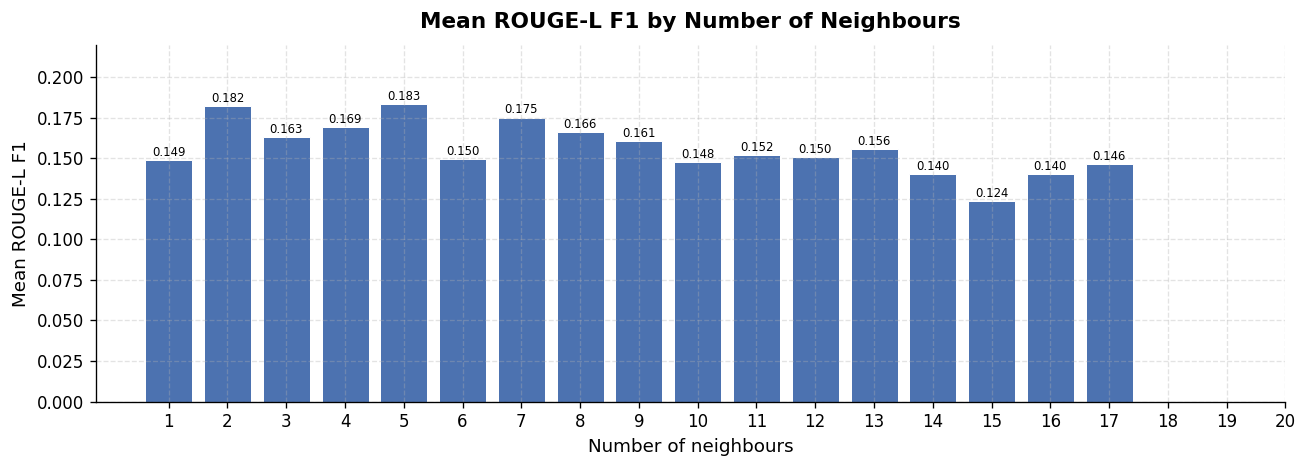

In [6]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = df.groupby('num_of_neighbors')['rougeL_f'].mean()
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

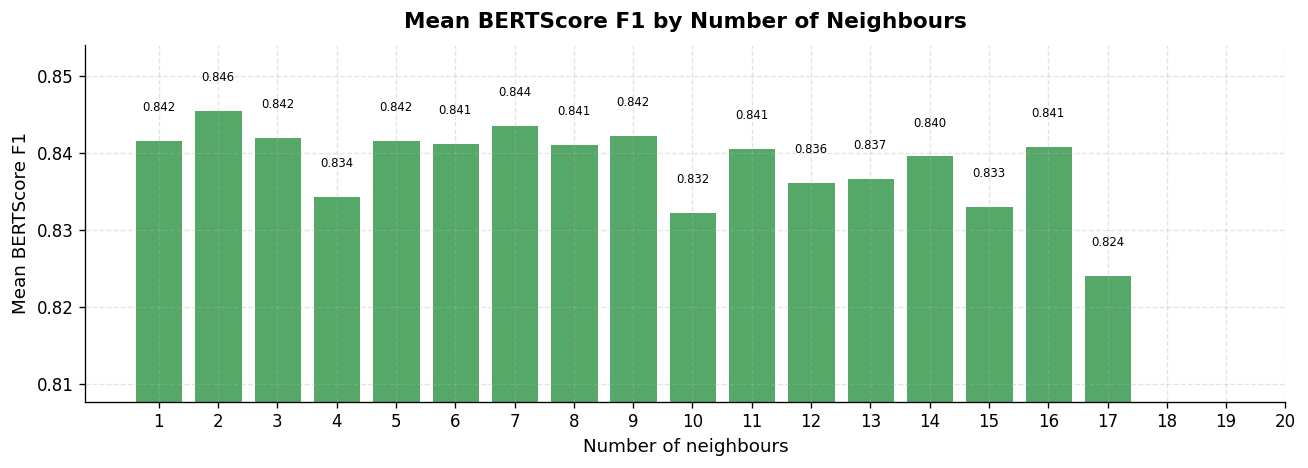

In [7]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = df.groupby('num_of_neighbors')['bertscore_f1'].mean()
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

Overall mean LLM accuracy: 2.503
Successfully generated (non-error): 147 / 200


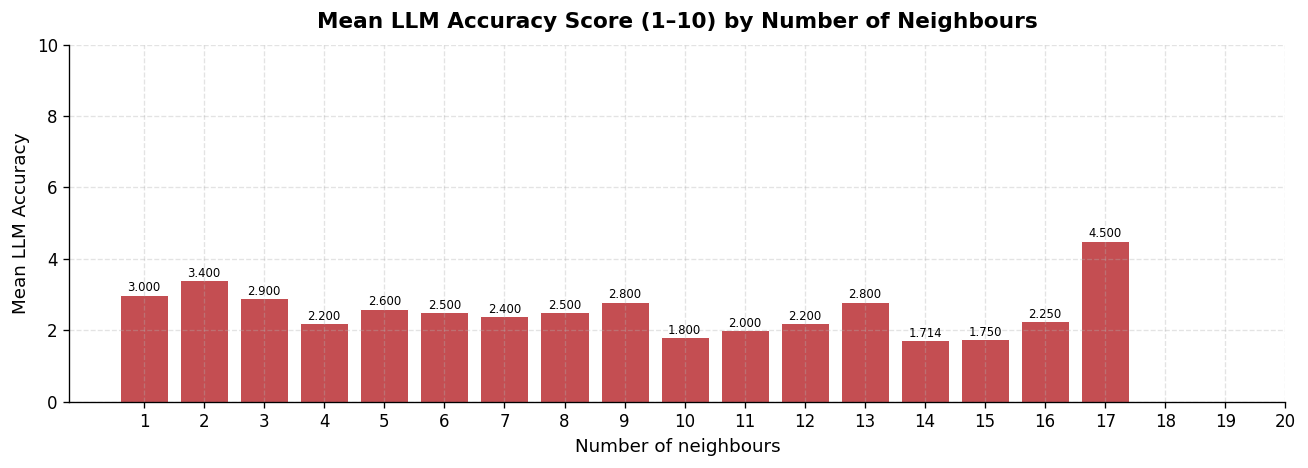

In [8]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = df.groupby('num_of_neighbors')['llm_accuracy'].mean()
overall_acc_mean = df['llm_accuracy'].mean()
num_successful = (~df['is_error']).sum()
print(f'Overall mean LLM accuracy: {overall_acc_mean:.3f}')
print(f'Successfully generated (non-error): {num_successful} / {len(df)}')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

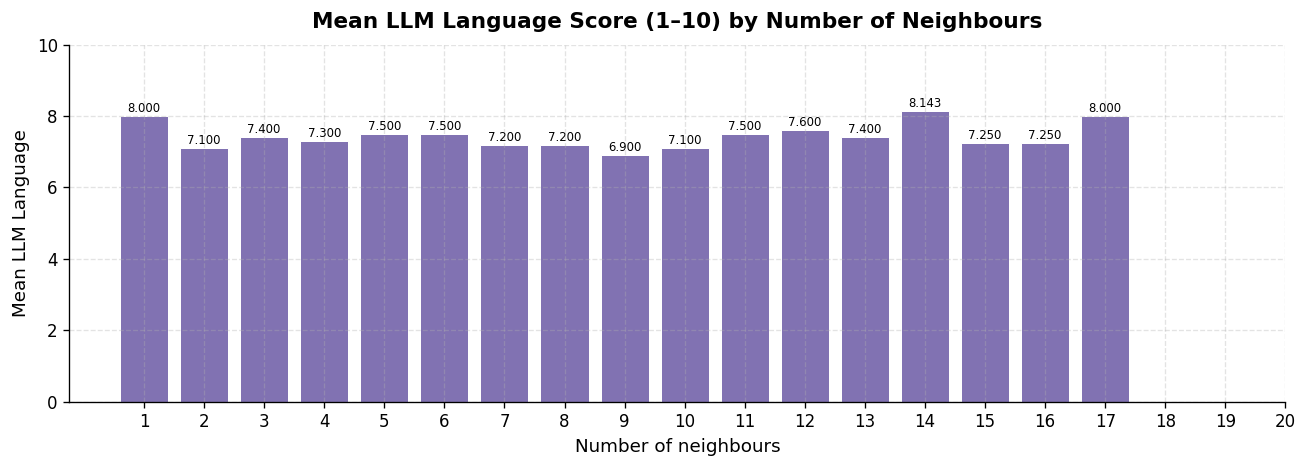

In [9]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = df.groupby('num_of_neighbors')['llm_language'].mean()
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

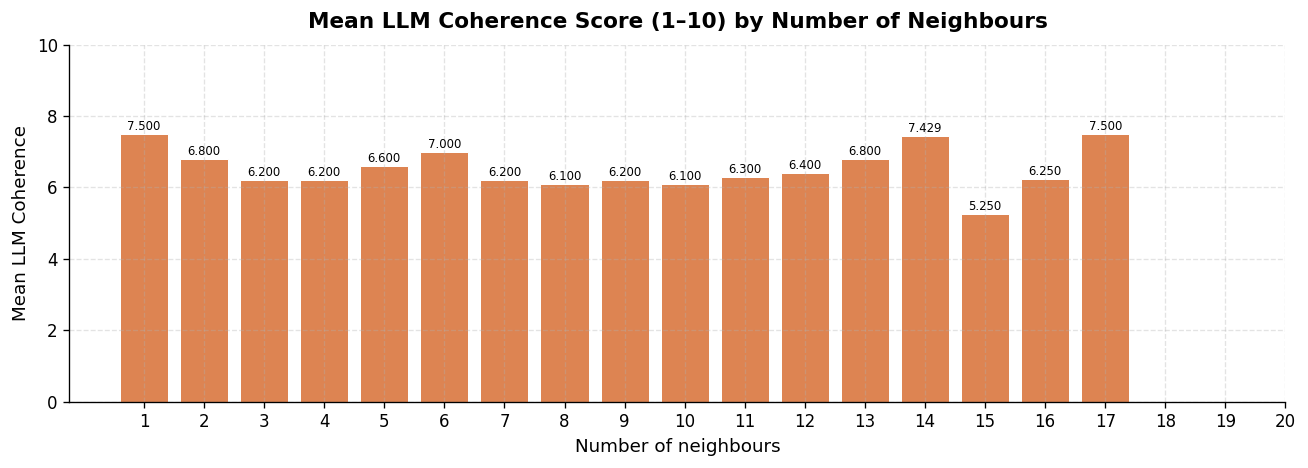

In [10]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = df.groupby('num_of_neighbors')['llm_coherence'].mean()
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

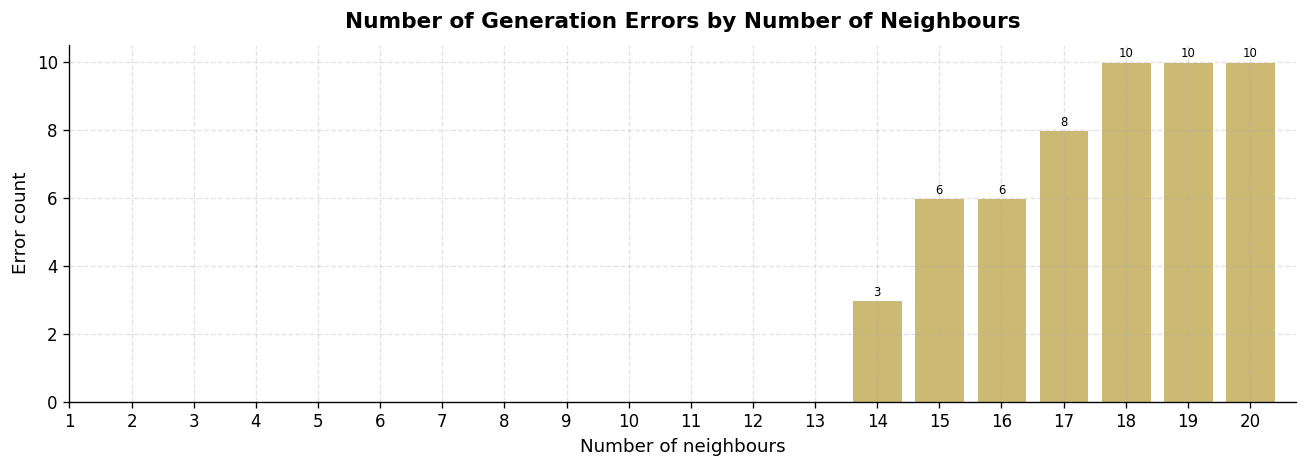

In [11]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('num_of_neighbors').size()
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [12]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_37828/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,112227,"The TrustZone technology, available in the vast majority of recent ARM processors, allows the execution of code inside a so-called secure world. It effectively provides hardware-isolated areas of the processor for sensitive data and code, i.e., a trusted execution environment (TEE). The OP-TEE framework provides a collection of toolchain, open-source libraries and secure kernel specifically geared to develop applications for TrustZone. This paper presents an in-depth performance- and energy-wise study of TrustZone using the OP-TEE framework, including secure storage and the cost of switching between secure and unsecure worlds, using emulated and hardware measurements.","This paper presents Open-TEE, a virtual, hardware-independent Trusted Execution Environment (TEE) implemented in software, which conforms to GlobalPlatform specifications. Developers can use the same tools they use for general software development to create and debug trusted applications on Open-TEE. Performance measurements and a user study show that Open-TEE is efficient and easy to use. Additionally, this paper introduces Nethammer, a remote Rowhammer attack that exploits parasitic effects in DRAM to modify memory cells without accessing them. The attack can be carried out on systems that use uncached memory or flush instructions while handling network requests. Finally, this paper describes Secloak, an ARM TrustZone-based solution that ensures reliable on-off control of peripherals on smart devices, even when the platform software is compromised.",1.0
1,137028,"Automatically generating accurate summaries from clinical reports could save a clinician's time, improve summary coverage, and reduce errors. We propose a sequence-to-sequence abstractive summarization model augmented with domain-specific ontological information to enhance content selection and summary generation. We apply our method to a dataset of radiology reports and show that it significantly outperforms the current state-of-the-art on this task in terms of rouge scores. Extensive human evaluation conducted by a radiologist further indicates that this approach yields summaries that are less likely to omit important details, without sacrificing readability or accuracy.","This paper presents a new application of the Adam algorithm, a stochastic optimization method for first-order gradient-based optimization of stochastic objective functions. The method is based on adaptive estimates of lower-order moments and is suitable for problems that are large in terms of data and/or parameters. It is also appropriate for non-stationary objectives and problems with very noisy and/or sparse gradients. The hyper-parameters have intuitive interpretations and typically require little tuning. The paper analyzes the theoretical convergence properties of the algorithm and provides a regret bound on the convergence rate that is comparable to the best known results under the online convex optimization framework. The method is tested on various datasets and compares favorably to other stochastic optimization methods.",1.0
2,95230,"Fatigue is the most vital factor of road fatalities and one manifestation of fatigue during driving is drowsiness. In this paper, we propose using deep Q-learning to analyze an electroencephalogram (EEG) dataset captured during a simulated endurance driving test. By measuring the correlation between drowsiness and driving performance, this experiment represents an important brain-computer interface (BCI) paradigm especially from an application perspective. We adapt the terminologies in the driving test to fit the reinforcement learning framework, thus formulate the drowsiness estimation problem as an optimization of a Q-learning task. By referring to the latest deep Q-Learning technologies and attending to the characteristics of EEG data, we tailor a deep Q-network for action proposition that can indirectly estimate drowsine

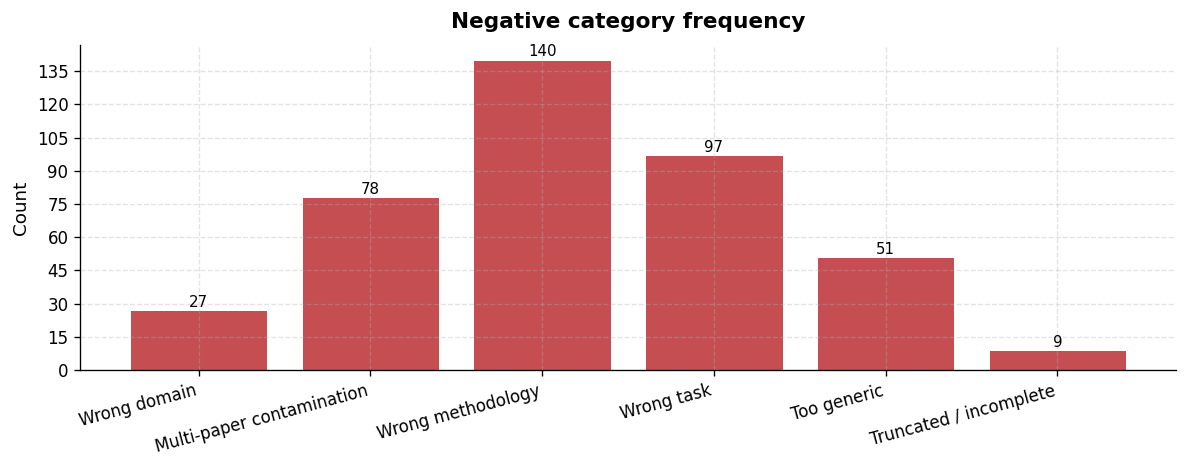

In [13]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


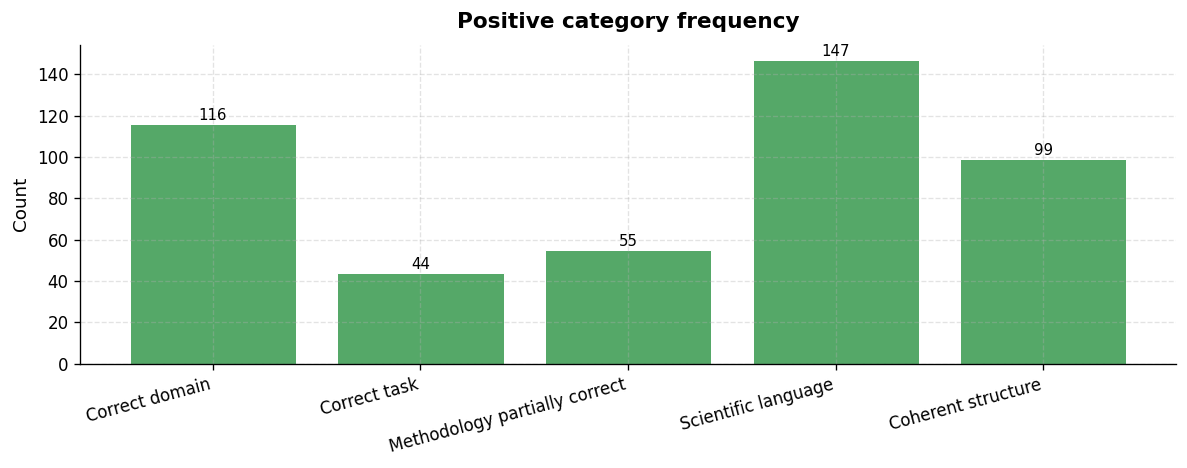

In [14]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()